# Circular Dataset Structures

Python version of `R/Circular Dataset Structures.Rmd` (and `Matlab/CircularDatasetStructures.m`).

Simulated circular datasets provide examples of effects on mean direction, concentration, and individual differences.
Fitted circular models (von Mises likelihood with a circular modulo link for $\mu$ and a softplus link for $\kappa$) are used to estimate these effects and compare hypotheses about their causes.

The models are written directly in `PyMC` and sampled with `nutpie`. The datasets are the ones simulated in the R version, exported by `R/Export Circular Datasets.R`, so all three versions model identical data.

Differences from the R version:

- Posterior densities of mean vectors are shown as clouds of posterior draws.
- Observations with high Pareto $\hat{k}$ in leave-one-out cross-validation are refitted exactly (as `loo(..., reloo = TRUE)` in R), rather than using moment matching.
- Treatment effects are coded without centring predictors, so intercepts are the control condition (equivalent to `0 + Intercept` in `brms`).

# Set up workspace

In [1]:
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import pymc as pm
import pytensor.tensor as pt
import arviz as az
from scipy.special import i0e, i1e, logsumexp
from scipy.stats import norm

from unwrap.link.pymc import circular_modulo, softplus

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

DATA_DIR = '../Matlab/circular_datasets'  # exported by "R/Export Circular Datasets.R"
SAMPLE_KWARGS = dict(draws=1000, tune=1000, chains=4,  # as brms defaults
                     nuts_sampler='nutpie', progressbar=False)
RELOO = True  # refit without observations with Pareto k > 0.7
rng = np.random.default_rng(120810506)  # ISBN Batschelet 1981

# colours (as in the R version)
col_kappa = '#1E78B5'  # kappa parameter
col_rho = '#F08024'  # mean vector length
col_sd = '#E74A29'  # SD and mean angle
col_obs = '#3E1F51'  # control observations
col_treat = '#006400'  # treatment observations

## Circular helper functions

In [2]:
def wrap_pi(x):
    return np.arctan2(np.sin(x), np.cos(x))

def softplus_np(x):
    return np.logaddexp(0, x)

def A1(k):
    # mean vector length of a von Mises distribution
    return i1e(k) / i0e(k)

def circ_mean(x, axis=None):
    return np.angle(np.mean(np.exp(1j * np.asarray(x)), axis=axis))

def circ_median(x):
    # angle minimising the mean circular distance to all points
    x = wrap_pi(np.ravel(x))
    cand = x[np.linspace(0, len(x) - 1, min(len(x), 1000)).astype(int)]
    dev = [np.mean(np.pi - np.abs(np.pi - np.abs(x - c))) for c in cand]
    return cand[np.argmin(dev)]

def unwrap_circular(x, axis=None):
    # remove discontinuities by centring on the mean direction
    mux = circ_mean(x, axis=axis)
    if axis is not None:
        mux = np.expand_dims(mux, axis)
    return wrap_pi(x - mux) + mux

def v_test(x, mu0):
    # Rayleigh test with a specified mean direction (normal approximation)
    n = len(x)
    V = np.abs(np.mean(np.exp(1j * x))) * np.cos(circ_mean(x) - mu0)
    return V, 1 - norm.cdf(V * np.sqrt(2 * n))

def draws(idata, name, **sel):
    # pooled posterior draws of one variable
    da = idata.posterior[name]
    if sel:
        da = da.sel(**sel)
    return da.stack(sample=('chain', 'draw')).values

## Plotting functions

In [3]:
def circ_base(ax, refline=0.0):
    # circular axes: zero at the top, clockwise rotation
    t = np.linspace(0, 2 * np.pi, 361)
    ax.plot(np.sin(t), np.cos(t), 'k-', lw=1)
    for a in np.arange(4) * np.pi / 2:
        ax.plot([0.95 * np.sin(a), 1.05 * np.sin(a)], [0.95 * np.cos(a), 1.05 * np.cos(a)], 'k-')
    if refline is not None:
        ax.plot([0, np.sin(refline)], [0, np.cos(refline)], '-', color='gray', lw=3)
    ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6)
    ax.set_aspect('equal'); ax.axis('off')

def circ_points(ax, angles, col):
    # stacked points in 5° bins
    binw = 2 * np.pi / 72
    b = np.round(np.mod(angles, 2 * np.pi) / binw).astype(int) % 72
    for ub in np.unique(b):
        r = 1 + 0.06 * np.arange(1, np.sum(b == ub) + 1)
        ax.scatter(r * np.sin(ub * binw), r * np.cos(ub * binw), s=12, color=col)

def circ_arrow(ax, mu, rho, col, lw=2):
    ax.annotate('', xy=(rho * np.sin(mu), rho * np.cos(mu)), xytext=(0, 0),
                arrowprops=dict(arrowstyle='-|>', color=col, lw=lw))

def draw_cloud(ax, mu, kappa, n=1000):
    # posterior distribution of mean vectors as a cloud of draws
    idx = rng.choice(len(mu), size=min(n, len(mu)), replace=False)
    rho = A1(kappa[idx])
    ax.scatter(rho * np.sin(mu[idx]), rho * np.cos(mu[idx]), s=4, color=(0.85, 0.2, 0.1),
               alpha=0.06, edgecolors='none')

def vert_hist(ax, x, title, lims, col, refval=0.0):
    ax.hist(x, bins=40, range=lims, orientation='horizontal', color=col, alpha=0.4)
    ax.axhline(refval, color='gray', lw=4)
    ax.set_ylim(*lims); ax.set_title(title)

## Model building functions

The likelihood uses the circular modulo link for $\mu$ and the softplus link for $\kappa$:

$$y \sim \mathcal{M}(\mathrm{mod}(\mu), \log(\exp(\eta_\kappa) + 1))$$

Since $\cos(y - \mathrm{mod}(\mu)) = \cos(y - \mu)$, parameters on the scale of $\mu$ are unbounded and may wrap around the circle.
Von Mises priors on these parameters are added as potentials, also applying the circular modulo.

In [4]:
def von_mises_logp(x, mu, kappa):
    return pm.logp(pm.VonMises.dist(mu=mu, kappa=kappa), circular_modulo(x - mu))

def fixed_model(y, mu_terms=(), kappa_terms=()):
    # mu_terms, kappa_terms: (name, predictor, (prior mean, prior sd)) for normal priors
    with pm.Model() as model:
        eta_mu = 0.0
        for name, xp, (m, s) in mu_terms:
            eta_mu = eta_mu + pm.Normal(name, mu=m, sigma=s) * xp
        eta_k = 0.0
        for name, xp, (m, s) in kappa_terms:
            eta_k = eta_k + pm.Normal(name, mu=m, sigma=s) * xp
        pm.VonMises('y', mu=circular_modulo(eta_mu + np.zeros(len(y))),
                    kappa=softplus(eta_k + np.zeros(len(y))), observed=wrap_pi(np.asarray(y)))
    return model

def individual_model(y, ID, x=None, mu_treatment=False, kappa_treatment=False,
                     beta0_prior=((0, 3 * np.pi / 2),), kappa_prior=((3, 3),),
                     sd_scale=0.5, betai_kappa=None):
    # mu = beta0 + betai, betai ~ vonMises(0, kappa_mu)
    # kappa = softplus(Intercept + r_ID), r_ID ~ N(0, sd) (non-centred)
    # with treatment x: beta0 ~ 1 + x, betai ~ 0 + ID + x:ID, kappa ~ 0 + Intercept + x + (1 + x|ID)
    y = np.asarray(y)
    ids, g = np.unique(ID, return_inverse=True)
    x = np.zeros(len(y)) if x is None else np.asarray(x, dtype=float)
    with pm.Model(coords={'ID': ids, 're': ['Intercept', 'x']}) as model:
        # population mean direction
        if beta0_prior is None:
            beta0 = 0.0  # anchored at 0°
        elif beta0_prior == 'uniform':
            beta0 = pm.Flat('b_beta0_Intercept')
            pm.Potential('beta0_prior', von_mises_logp(beta0, 0.0, 1e-16))
        else:
            beta0 = pm.Normal('b_beta0_Intercept', *beta0_prior[0])
        if mu_treatment:
            beta0 = beta0 + pm.Normal('b_beta0_x', *beta0_prior[1]) * x
        # individual biases and the concentration across them
        betai = pm.Flat('b_betai', dims='ID')
        mu = beta0 + betai[g]
        if betai_kappa is not None:
            pm.Potential('betai_prior', von_mises_logp(betai, 0.0, betai_kappa).sum())
        else:
            skm = pm.Flat('softkappamu')
            # expect high concentration (low variation), as in brms: no Jacobian
            pm.Potential('softkappamu_prior',
                         pm.logp(pm.LogNormal.dist(mu=np.log(15), sigma=0.6), softplus(skm)))
            kappa_mu = pm.Deterministic('kappa_mu', softplus(skm))
            pm.Potential('betai_prior', von_mises_logp(betai, 0.0, kappa_mu).sum())
            if mu_treatment:
                betaix = pm.Flat('b_betai_x', dims='ID')
                mu = mu + betaix[g] * x
                skmx = pm.Normal('softkappamux', 0, 1.0)
                kappa_mu_x = pm.Deterministic('kappa_mu_x', softplus(skm + skmx))
                pm.Potential('betai_x_prior', von_mises_logp(betai + betaix, 0.0, kappa_mu_x).sum())
        # concentration
        eta_k = pm.Normal('b_kappa_Intercept', *kappa_prior[0])
        if kappa_treatment:
            eta_k = eta_k + pm.Normal('b_kappa_x', *kappa_prior[1]) * x
            sds = pm.HalfStudentT('sd_ID__kappa', nu=3, sigma=np.asarray(sd_scale, dtype=float), dims='re')
            # LKJ(1) prior for a 2x2 correlation matrix: uniform correlation
            rho = pm.Uniform('cor_ID__kappa_Intercept__kappa_x', -1, 1)
            chol = pt.stack([pt.stack([sds[0], 0.0]),
                             pt.stack([sds[1] * rho, sds[1] * pt.sqrt(1 - rho**2)])])
            z = pm.Normal('z_ID__kappa', 0, 1, dims=('ID', 're'))
            r = pm.Deterministic('r_ID__kappa', pt.dot(z, chol.T), dims=('ID', 're'))
            eta_k = eta_k + r[g, 0] + r[g, 1] * x
        else:
            sd = pm.HalfStudentT('sd_ID__kappa', nu=3, sigma=sd_scale)
            z = pm.Normal('z_ID__kappa', 0, 1, dims='ID')
            r = pm.Deterministic('r_ID__kappa', sd * z, dims='ID')
            eta_k = eta_k + r[g]
        pm.VonMises('y', mu=circular_modulo(mu), kappa=softplus(eta_k), observed=wrap_pi(y))
    return model

## Fitting, summaries and model comparison

In [5]:
def fit(model, target_accept=0.8, loglik=True):
    with model:
        idata = pm.sample(**SAMPLE_KWARGS, target_accept=target_accept,
                          random_seed=int(rng.integers(2**31)))
        if loglik:
            pm.compute_log_likelihood(idata, progressbar=False)
    return idata

def summary(idata, var_names, circ_var_names=()):
    # circular parameters are summarised after unwrapping (r_hat_raw: before unwrapping)
    post = idata.posterior[var_names].copy()
    for v in circ_var_names:
        post[v] = (post[v].dims, unwrap_circular(post[v].values, axis=None)
                   if post[v].ndim == 2 else
                   np.stack([unwrap_circular(post[v].values[..., j])
                             for j in range(post[v].shape[-1])], axis=-1))
    sm = az.summary(post, kind='all', hdi_prob=0.95)
    sm['r_hat_raw'] = az.summary(idata.posterior[var_names], kind='diagnostics')['r_hat']
    return sm

def loo(idata, build, n_obs, name, target_accept=0.8, threshold=0.7):
    # PSIS-LOO; observations with Pareto k > threshold are refitted exactly
    lo = az.loo(idata, pointwise=True)
    bad = np.where(lo.pareto_k.values > threshold)[0]
    if len(bad) and RELOO:
        print(f'{name}: {len(bad)} observation(s) with Pareto k > {threshold}, refitting without them')
        loo_i = lo.loo_i.values.copy()
        for i in bad:
            keep = np.ones(n_obs, dtype=bool); keep[i] = False
            idata_i = fit(build(keep), target_accept, loglik=False)
            # log predictive density of the left out observation, using the full model
            ll = pm.compute_log_likelihood(idata_i, model=build(np.ones(n_obs, dtype=bool)),
                                           extend_inferencedata=False, progressbar=False)['y']
            ll_i = ll.values[..., i].ravel()
            loo_i[i] = logsumexp(ll_i) - np.log(len(ll_i))
        lo.loo_i.values[:] = loo_i
        lo['elpd_loo'] = loo_i.sum()
        lo['se'] = np.sqrt(n_obs * np.var(loo_i, ddof=1))
        lo['warning'] = False
    elif len(bad):
        print(f'{name}: {len(bad)} observation(s) with Pareto k > {threshold}')
    return lo

def elpd_diff(lo1, lo2):
    # ELPD difference (first minus second) and its standard error, as in loo_compare
    d = lo1.loo_i.values - lo2.loo_i.values
    return f'{d.sum():.1f} ± {np.sqrt(len(d)) * np.std(d, ddof=1):.1f}'

# Divergence from home direction

<img src="../R/icons/ant.png" width="260">

*Desert ants of the genus *Cataglyphis* are known for their use of path integration (dead reckoning) to return to their nest. Disruption of visual orientation cues can result in deviations from the expected homewards direction.*

Return directions are compared with the expected home direction (0°).
The data ($n = 20$) were generated from a distribution with a mean that differs from the expected direction by only 15° ($\kappa = 10$).

In [6]:
y_div = pd.read_csv(f'{DATA_DIR}/divergence.csv')['y'].values

print(f'Proportion left of 0°: {np.mean(wrap_pi(y_div) < 0):.2f}')
V, p = v_test(y_div, 0.0)
print(f'v-test (expected direction 0°): V = {V:.3f}, p = {p:.2g}')

Proportion left of 0°: 0.75
v-test (expected direction 0°): V = 0.950, p = 9.3e-10


## Fit the model

Each of $\mu$ and $\kappa$ require a single parameter estimate (an intercept).
Highest prior density for $\mu$ is within $\pi$ of the mean, and for $\kappa$ in $\kappa > 1$.

In [7]:
n_div = len(y_div)
def build_divergence(keep, y=y_div):
    return fixed_model(y[keep],
                       mu_terms=[('b_Intercept', 1.0, (0, 2 * np.pi))],
                       kappa_terms=[('b_kappa_Intercept', 1.0, (3, 3))])
idata_div = fit(build_divergence(np.ones(n_div, dtype=bool)))
summary(idata_div, ['b_Intercept', 'b_kappa_Intercept'], ['b_Intercept'])

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat,r_hat_raw
b_Intercept,-0.225,0.079,-0.392,-0.078,0.001,0.001,3276.0,1902.0,1.0,1.0
b_kappa_Intercept,9.003,2.022,5.414,13.187,0.036,0.036,3410.0,2369.0,1.0,1.0


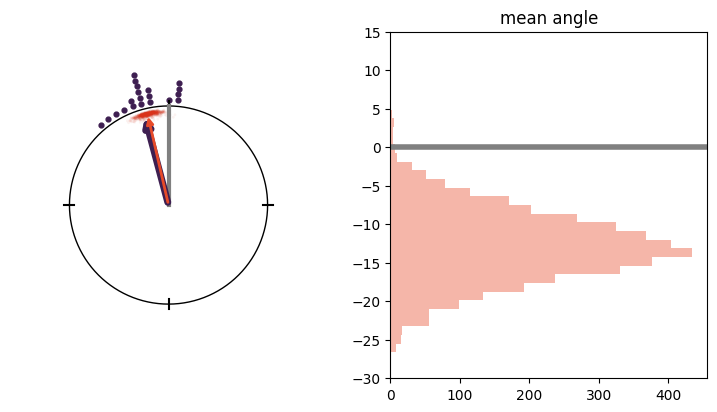

mu left of expected angle: 99.6%


In [8]:
mu_d, k_d = draws(idata_div, 'b_Intercept'), softplus_np(draws(idata_div, 'b_kappa_Intercept'))
fig, axs = plt.subplots(1, 2, figsize=(9, 4.5))
circ_base(axs[0]); circ_points(axs[0], y_div, col_obs)
draw_cloud(axs[0], mu_d, k_d)
circ_arrow(axs[0], np.deg2rad(-15), A1(10), col_obs, 5)
circ_arrow(axs[0], circ_median(mu_d), A1(np.median(k_d)), col_sd, 2)
vert_hist(axs[1], np.rad2deg(unwrap_circular(mu_d)), 'mean angle', (-30, 15), col_sd)
plt.show()
print(f'mu left of expected angle: {100 * np.mean(wrap_pi(mu_d) < 0):.1f}%')

The data show a trend away from the expected angle (75% of points fall to the left of 0°), and the fitted model indicates that the mean direction is to the left of the expected direction in $>99\%$ of $\mu$ estimates.

## Test the expected angle hypothesis

A model where the mean direction is fixed at the expected direction (no $\mu$ parameter) is compared with the model above using leave-one-out cross-validation (LOO-CV).

In [9]:
def build_expect(keep, y=y_div):
    return fixed_model(y[keep], kappa_terms=[('b_kappa_Intercept', 1.0, (3, 3))])
idata_expect = fit(build_expect(np.ones(n_div, dtype=bool)))
loo_div = loo(idata_div, build_divergence, n_div, 'model_divergence')
loo_expect = loo(idata_expect, build_expect, n_div, 'model_expect')
print('ELPD difference (divergence - expected):', elpd_diff(loo_div, loo_expect))
az.compare({'model_divergence': loo_div, 'model_expect': loo_expect})

ELPD difference (divergence - expected): 4.2 ± 1.6


,rank,elpd_loo,p_loo,elpd_diff,weight,se,dse,warning,scale
model_divergence,0,-2.336403,0.67351,0.000000,1.000000e+00,1.305425,0.000000,False,log
model_expect,1,-6.551845,0.27224,4.215442,5.551115e-17,2.097181,1.603574,False,log


The model for a divergent mean direction has higher expected log predictive density (ELPD) than the model for the expected direction.
This ELPD difference is $>2\times$ larger than its standard error, so we can state with some confidence that the hypothesis of a divergence from the expected direction is more likely than the hypothesis of alignment with the expected direction.

If the expected direction is not 0°, the data are aligned with the expected angle (here −15°, the true mean), and both models fitted to the aligned data.

In [10]:
y_aligned = y_div - np.deg2rad(-15)
build_true = lambda keep: build_expect(keep, y_aligned)
build_false = lambda keep: build_divergence(keep, y_aligned)
idata_true = fit(build_true(np.ones(n_div, dtype=bool)))
idata_false = fit(build_false(np.ones(n_div, dtype=bool)))
print(np.round(np.rad2deg(summary(idata_false, ['b_Intercept'], ['b_Intercept'])
                          .loc['b_Intercept', ['mean', 'sd', 'hdi_2.5%', 'hdi_97.5%']].astype(float))))
loo_true = loo(idata_true, build_true, n_div, 'model_true')
loo_false = loo(idata_false, build_false, n_div, 'model_false')
print('ELPD difference (expected at -15° - divergent):', elpd_diff(loo_true, loo_false))
az.compare({'model_true': loo_true, 'model_false': loo_false})

mean          2.0
sd            4.0
hdi_2.5%     -6.0
hdi_97.5%    11.0
Name: b_Intercept, dtype: float64
ELPD difference (expected at -15° - divergent): 0.8 ± 0.3


,rank,elpd_loo,p_loo,elpd_diff,weight,se,dse,warning,scale
model_true,0,-1.558459,0.165307,0.000000,1.000000e+00,1.235270,0.000000,False,log
model_false,1,-2.326030,0.631663,0.767571,9.714451e-17,1.285051,0.325636,False,log


Now the expected direction model has higher predictive power, even though both find a similar mean direction.
If the divergence model had higher predictive power, but within one standard error of the expected direction model, we could not rule out the possibility that the expected direction is the true direction, though evidence would be weaker.

# Change in direction

<img src="../R/icons/sandhopper.png" width="420">

*Sandhoppers (*Talitridae*) forage along beaches, following the movement of the sea to avoid drying out. Their movement is guided by celestial cues, including the moon.*

The treatment induces a rightward turn of 30°, changing $\mu$ from 180° to 210° ($\kappa = 3$).

## Fit the model

The treatment indicator $x$ is used as a predictor of both $\mu$ and $\kappa$, without centring, so the intercepts describe the control condition and the `x` coefficients the change caused by the treatment.

In [11]:
dt_delta = pd.read_csv(f'{DATA_DIR}/delta.csv')
n_delta = len(dt_delta)

def build_treatment(dt, mu_x=True, kappa_x=True):
    def build(keep):
        d = dt[keep]
        x = d['x'].values.astype(float)
        mu_terms = [('b_Intercept', 1.0, (0, 3 * np.pi / 2))]
        kappa_terms = [('b_kappa_Intercept', 1.0, (3, 3))]
        if mu_x:
            mu_terms.append(('b_x', x, (0, np.pi / 2)))
        if kappa_x:
            kappa_terms.append(('b_kappa_x', x, (0, 3)))
        return fixed_model(d['y'].values, mu_terms, kappa_terms)
    return build

build_delta = build_treatment(dt_delta)
idata_delta = fit(build_delta(np.ones(n_delta, dtype=bool)))
summary(idata_delta, ['b_Intercept', 'b_x', 'b_kappa_Intercept', 'b_kappa_x'], ['b_Intercept', 'b_x'])

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat,r_hat_raw
b_Intercept,3.123,0.189,2.763,3.506,0.013,0.003,206.0,1868.0,1.03,1.76
b_x,0.530,0.280,-0.057,1.052,0.038,0.005,54.0,1579.0,1.05,1.53
b_kappa_Intercept,2.165,0.691,0.932,3.628,0.016,0.013,1944.0,2073.0,1.00,1.00
b_kappa_x,-0.231,0.941,-1.992,1.637,0.021,0.015,1968.0,2037.0,1.00,1.00


The control mean direction is close to the wrap point ($\pm\pi$), so raw estimates for `b_Intercept` can appear in both positive and negative directions (`r_hat_raw`).
After unwrapping, the chains agree (`r_hat`).

Predictions for the control use `b_Intercept` and `b_kappa_Intercept`, and for the treatment `b_Intercept + b_x` and `b_kappa_Intercept + b_kappa_x`.

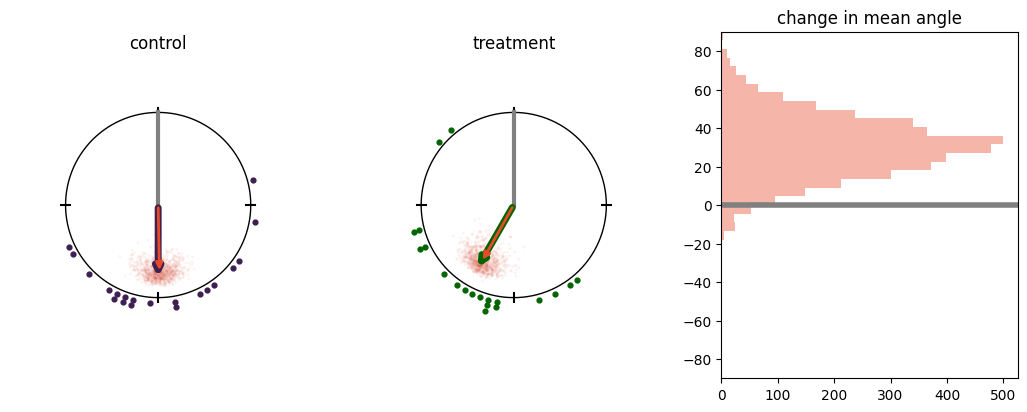

Rightwards turn: 97.3% of estimates
Median turn: 30°
95% CI of the turn: -1° to 63°


In [12]:
def plot_treatment(idata, dt, mu_true, kappa_true):
    b0, bx = draws(idata, 'b_Intercept'), draws(idata, 'b_x')
    k0, kx = draws(idata, 'b_kappa_Intercept'), draws(idata, 'b_kappa_x')
    fig, axs = plt.subplots(1, 3, figsize=(13, 4.5))
    for ax, cond, mu, kp, col in [(axs[0], 0, b0, softplus_np(k0), col_obs),
                                  (axs[1], 1, b0 + bx, softplus_np(k0 + kx), col_treat)]:
        circ_base(ax); circ_points(ax, dt['y'][dt['x'] == cond].values, col)
        draw_cloud(ax, mu, kp)
        circ_arrow(ax, mu_true[cond], A1(kappa_true[cond]), col, 5)
        circ_arrow(ax, circ_median(mu), A1(np.median(kp)), col_sd, 2)
        ax.set_title(['control', 'treatment'][cond])
    return axs[2]

ax = plot_treatment(idata_delta, dt_delta, np.deg2rad([180, 210]), [3, 3])
bx = draws(idata_delta, 'b_x')
vert_hist(ax, np.rad2deg(wrap_pi(bx)), 'change in mean angle', (-90, 90), col_sd)
plt.show()
print(f'Rightwards turn: {100 * np.mean(wrap_pi(bx) > 0):.1f}% of estimates')
print(f'Median turn: {np.rad2deg(circ_median(bx)):.0f}°')
print('95% CI of the turn: {:.0f}° to {:.0f}°'.format(*np.quantile(np.rad2deg(unwrap_circular(bx)), [0.025, 0.975])))

Uncertainty in the example data results in a wide range of posterior estimates for the treatment direction.
Nonetheless, most estimates for change in $\mu$ are to the right of 0° (percentage above), suggesting a rightwards change in direction.

## Test the direction change hypothesis

Models with treatment effects on $\kappa$ only, and with no effects of treatment, are compared with the full model.

In [13]:
build_kappadelta = build_treatment(dt_delta, mu_x=False)
build_nodelta = build_treatment(dt_delta, mu_x=False, kappa_x=False)
idata_kappadelta = fit(build_kappadelta(np.ones(n_delta, dtype=bool)))
idata_nodelta = fit(build_nodelta(np.ones(n_delta, dtype=bool)))
display(summary(idata_kappadelta, ['b_Intercept', 'b_kappa_Intercept', 'b_kappa_x'], ['b_Intercept']))
display(summary(idata_nodelta, ['b_Intercept', 'b_kappa_Intercept'], ['b_Intercept']))
loo_delta = loo(idata_delta, build_delta, n_delta, 'model_delta')
loo_kappadelta = loo(idata_kappadelta, build_kappadelta, n_delta, 'model_kappadelta')
loo_nodelta = loo(idata_nodelta, build_nodelta, n_delta, 'model_nodelta')
print('ELPD difference (delta - no delta):', elpd_diff(loo_delta, loo_nodelta))
print('ELPD difference (kappa delta - no delta):', elpd_diff(loo_kappadelta, loo_nodelta))
az.compare({'model_delta': loo_delta, 'model_kappadelta': loo_kappadelta, 'model_nodelta': loo_nodelta})

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat,r_hat_raw
b_Intercept,-2.913,0.145,-3.207,-2.634,0.003,0.002,2291.0,2479.0,1.0,2.41
b_kappa_Intercept,2.047,0.696,0.715,3.444,0.017,0.012,1654.0,1948.0,1.0,1.00
b_kappa_x,-0.249,0.996,-2.158,1.708,0.025,0.018,1529.0,1921.0,1.0,1.00


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat,r_hat_raw
b_Intercept,-2.899,0.139,-3.185,-2.630,0.002,0.003,3330.0,2485.0,1.0,2.41
b_kappa_Intercept,1.893,0.454,1.030,2.795,0.008,0.007,3644.0,2585.0,1.0,1.00


ELPD difference (delta - no delta): -0.2 ± 2.0
ELPD difference (kappa delta - no delta): -1.2 ± 0.3


,rank,elpd_loo,p_loo,elpd_diff,weight,se,dse,warning,scale
model_nodelta,0,-52.519936,2.095800,0.000000,5.506077e-01,5.523051,0.000000,False,log
model_delta,1,-52.744730,4.122453,0.224794,4.493923e-01,5.133356,1.932723,False,log
model_kappadelta,2,-53.703755,3.262315,1.183819,6.465342e-16,5.727333,0.324467,False,log


In this case there is uncertainty about the effect of treatment on direction.
Although most estimates from the model with a change in direction indicate a rightwards turn, these differences could also be explained well by a null model with no change (ELPD difference within its standard error).
Since the median estimate is close to the true value of 30°, the model's estimates appear to be robust, if not conclusive.
Conversely, there is no evidence for an effect of treatment on concentration, since `model_kappadelta` has lower predictive density than the null model (`model_nodelta`), although this difference is small.

# Change in concentration

<img src="../R/icons/honeybee.png" width="420">

*Honeybees performing a "waggle dance" on a horizontal observation hive that view a green light-spot, orient their dances as if viewing the sun. The concentration of a series of dance directions decreases when the brightness of this light spot is reduced.*

The treatment has the same $\mu$ (0°) as the control, but $\kappa$ decreases from 3 to 0.5.
The same model as for the change in direction is used.

In [14]:
dt_conc = pd.read_csv(f'{DATA_DIR}/conc.csv')
n_conc = len(dt_conc)
build_conc = build_treatment(dt_conc)
idata_conc = fit(build_conc(np.ones(n_conc, dtype=bool)))
print(f"mu estimates to the left of 0°: {100 * np.mean(wrap_pi(draws(idata_conc, 'b_x')) < 0):.0f}%")
summary(idata_conc, ['b_Intercept', 'b_x', 'b_kappa_Intercept', 'b_kappa_x'], ['b_Intercept', 'b_x'])

mu estimates to the left of 0°: 59%


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat,r_hat_raw
b_Intercept,0.187,0.134,-0.074,0.451,0.003,0.003,2523.0,2390.0,1.0,1.0
b_x,-0.062,0.321,-0.663,0.601,0.006,0.006,2727.0,2297.0,1.0,1.0
b_kappa_Intercept,3.372,0.902,1.737,5.219,0.022,0.017,1728.0,1597.0,1.0,1.0
b_kappa_x,-2.456,1.102,-4.654,-0.371,0.027,0.020,1705.0,1814.0,1.0,1.0


The model successfully recovers a large change in $\kappa$ caused by the treatment, alongside only a negligible potential change in $\mu$ (similar posterior density to the left and right of 0°).

Since $\kappa$ is estimated on the inverse-softplus scale, estimates for control and treatment are softplus transformed before calculating their difference.

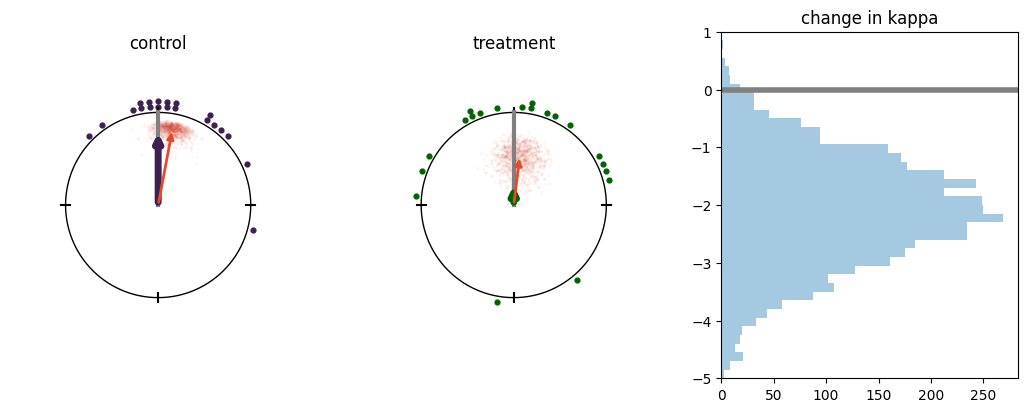

Reduction in kappa: 99.1% of estimates


In [15]:
ax = plot_treatment(idata_conc, dt_conc, [0.0, 0.0], [3, 0.5])
k0, kx = draws(idata_conc, 'b_kappa_Intercept'), draws(idata_conc, 'b_kappa_x')
vert_hist(ax, softplus_np(k0 + kx) - softplus_np(k0), 'change in kappa', (-5, 1), col_kappa)
plt.show()
print(f'Reduction in kappa: {100 * np.mean(kx < 0):.1f}% of estimates')

Although there is some uncertainty in the particular size of the change in $\kappa$, nearly all posterior estimates (percentage above) support a treatment effect that decreases $\kappa$.

## Test the concentration change hypothesis

In [16]:
build_conc_kappa = build_treatment(dt_conc, mu_x=False)
build_conc_nokappa = build_treatment(dt_conc, mu_x=False, kappa_x=False)
idata_conc_kappa = fit(build_conc_kappa(np.ones(n_conc, dtype=bool)))
idata_conc_nokappa = fit(build_conc_nokappa(np.ones(n_conc, dtype=bool)))
display(summary(idata_conc_kappa, ['b_Intercept', 'b_kappa_Intercept', 'b_kappa_x'], ['b_Intercept']))
display(summary(idata_conc_nokappa, ['b_Intercept', 'b_kappa_Intercept'], ['b_Intercept']))
loo_conc = loo(idata_conc, build_conc, n_conc, 'model_conc')
loo_conc_kappa = loo(idata_conc_kappa, build_conc_kappa, n_conc, 'model_conc_kappa')
loo_conc_nokappa = loo(idata_conc_nokappa, build_conc_nokappa, n_conc, 'model_conc_nokappa')
print('ELPD difference (kappa only - no kappa):', elpd_diff(loo_conc_kappa, loo_conc_nokappa))
print('ELPD difference (mu & kappa - kappa only):', elpd_diff(loo_conc, loo_conc_kappa))
az.compare({'model_conc': loo_conc, 'model_conc_kappa': loo_conc_kappa, 'model_conc_nokappa': loo_conc_nokappa})

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat,r_hat_raw
b_Intercept,0.179,0.121,-0.063,0.417,0.002,0.002,2498.0,2283.0,1.0,1.0
b_kappa_Intercept,3.336,0.869,1.664,5.021,0.023,0.016,1516.0,1972.0,1.0,1.0
b_kappa_x,-2.292,1.029,-4.492,-0.475,0.027,0.019,1504.0,1938.0,1.0,1.0


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat,r_hat_raw
b_Intercept,0.163,0.136,-0.107,0.422,0.002,0.002,3506.0,2741.0,1.0,1.0
b_kappa_Intercept,1.865,0.476,0.948,2.815,0.008,0.007,3837.0,2836.0,1.0,1.0


ELPD difference (kappa only - no kappa): 2.2 ± 2.4
ELPD difference (mu & kappa - kappa only): -1.1 ± 0.4


,rank,elpd_loo,p_loo,elpd_diff,weight,se,dse,warning,scale
model_conc_kappa,0,-50.641306,2.980600,0.000000,0.887867,5.753873,0.000000,False,log
model_conc,1,-51.724269,4.015571,1.082963,0.000000,5.668365,0.353530,False,log
model_conc_nokappa,2,-52.834297,2.279943,2.192991,0.112133,6.012758,2.357018,False,log


In this case, model comparison is less conclusive than the posterior estimates.
The model with an effect of treatment on $\kappa$ only predicts the data better than the model with no effects of treatment, but this difference is small relative to its standard error.
With this sample size, cross-validation therefore provides only weak support for the change in concentration indicated by the posterior estimates.
As we might have also expected, the effect of treatment on $\mu$, present in the original model but not the $\kappa$-only model, does not improve predictive density, so there is little evidence that the treatment affects $\mu$.

# High inter-individual correlation

<img src="../R/icons/moth.png" width="500">

*Tethered Bogong moths can be induced to fly in "flight simulators", which allows repeated measurements of flight directions across multiple individuals simultaneously. Individual directional biases may differ somewhat, but are typically highly correlated, aligning with the population's migratory direction.*

Each individual's headings are concentrated ($\kappa = 5$) around its own bias $\mu_i = \beta_0 + \beta_i$, and individual biases are moderately concentrated ($\kappa_\mu = 2$).

## Fit the model

$\beta_0$ is a single estimate across individuals, $\beta_i$ an offset for each individual with the prior $\beta_i \sim \mathcal{M}(0, \kappa_\mu)$, and $\kappa_\mu$ (estimated as its inverse softplus, `softkappamu`) has the prior $\log \kappa_\mu \sim \mathcal{N}(\log 15, 0.6)$.
Individual differences in $\kappa$ are normally distributed (inverse-softplus scale) with standard deviation $\sigma_\kappa \sim \mathrm{Half}\mathcal{T}(3, 0, 0.5)$.

In [17]:
def plot_individuals(idata, dt, mu_true, kappa_true, kappa_mu_true, kappa_pop_true, title):
    J = len(mu_true)
    has_b0 = 'b_beta0_Intercept' in idata.posterior
    b0 = draws(idata, 'b_beta0_Intercept') if has_b0 else 0.0
    k0 = draws(idata, 'b_kappa_Intercept')
    ids = idata.posterior['ID'].values
    fig, axs = plt.subplots(3, 4, figsize=(12, 9))
    axs = axs.ravel()
    for i, idv in enumerate(ids):
        ax = axs[i]; circ_base(ax)
        circ_points(ax, dt['y'][dt['ID'] == idv].values, col_obs)
        mu = b0 + draws(idata, 'b_betai', ID=idv)
        kp = softplus_np(k0 + draws(idata, 'r_ID__kappa', ID=idv))
        draw_cloud(ax, mu, kp)
        circ_arrow(ax, mu_true[i], A1(kappa_true[i]), col_obs, 4)
        circ_arrow(ax, circ_median(mu), A1(np.median(kp)), col_sd, 2)
    ax = axs[J]; circ_base(ax); ax.set_title('individual biases')
    circ_points(ax, mu_true, col_rho)
    circ_arrow(ax, 0.0, A1(kappa_mu_true), col_rho, 4)
    if 'kappa_mu' in idata.posterior:
        kmu = draws(idata, 'kappa_mu')
        draw_cloud(ax, b0 * np.ones_like(kmu), kmu)
        circ_arrow(ax, circ_mean(b0), A1(np.median(kmu)), col_sd, 2)
    vert_hist(axs[J + 1], softplus_np(k0), 'population kappa', (0, 10), col_kappa, kappa_pop_true)
    fig.suptitle(title)
    plt.show()

ind_vars = ['b_beta0_Intercept', 'b_betai', 'kappa_mu', 'b_kappa_Intercept', 'sd_ID__kappa', 'r_ID__kappa']
ind_circ = ['b_beta0_Intercept', 'b_betai']

dt_high = pd.read_csv(f'{DATA_DIR}/highcorr.csv')
true_high = pd.read_csv(f'{DATA_DIR}/highcorr_true.csv')
idata_high = fit(individual_model(dt_high['y'], dt_high['ID']))
summary(idata_high, ind_vars, ind_circ)

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat,r_hat_raw
b_beta0_Intercept,0.067,0.239,-0.392,0.492,0.016,0.008,238.0,563.0,1.01,1.01
b_betai[1],-0.431,0.258,-0.912,0.070,0.015,0.007,285.0,748.0,1.01,1.01
b_betai[2],0.317,0.253,-0.149,0.811,0.015,0.007,283.0,813.0,1.01,1.01
b_betai[3],-0.548,0.252,-1.030,-0.068,0.015,0.007,270.0,666.0,1.01,1.01
b_betai[4],-0.055,0.254,-0.524,0.443,0.015,0.007,271.0,744.0,1.01,1.01
b_betai[5],-0.257,0.253,-0.744,0.224,0.015,0.007,272.0,728.0,1.01,1.01
b_betai[6],-0.367,0.258,-0.887,0.105,0.016,0.007,275.0,765.0,1.01,1.01
b_betai[7],0.902,0.259,0.426,1.410,0.015,0.007,281.0,758.0,1.01,1.01
b_betai[8],0.721,0.256,0.271,1.249,0.016,0.007,271.0,735.0,1.01,1.01
b_betai[9],-1.391,0.264,-1.912,-0.889,0.016,0.007,268.0,811.0,1.01,1.01


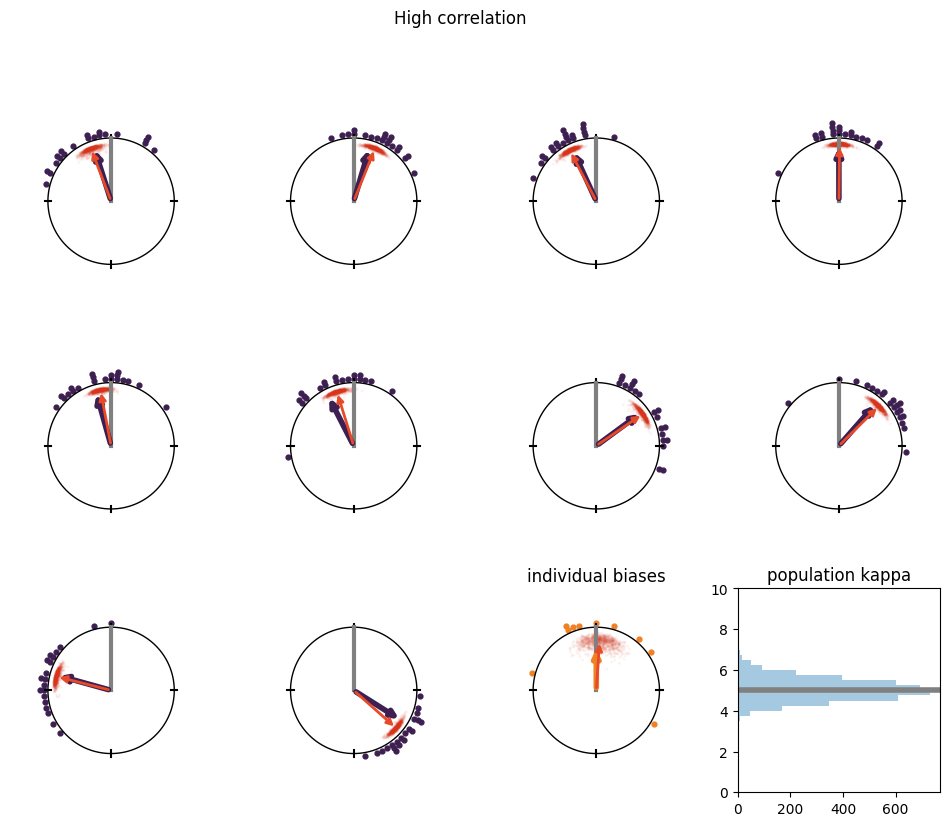

softplus(b_kappa_Intercept) > true kappa: 52.1%


In [18]:
plot_individuals(idata_high, dt_high, np.deg2rad(true_high['mu'].values), np.full(len(true_high), 5.0),
                 2.0, 5.0, 'High correlation')
print(f"softplus(b_kappa_Intercept) > true kappa: "
      f"{100 * np.mean(softplus_np(draws(idata_high, 'b_kappa_Intercept')) > 5.0):.1f}%")

The estimates of $\kappa_\mu$ have a slight positive bias, due to a combination of low sample size and our prior to higher values.
The model nonetheless recovers good estimates of $\beta_0$ and $\beta_i$ (overlap of shaded regions with dark purple arrows), as well as population $\kappa$, the concentration of the average individual, which needs to be distinguished from individual differences and the concentration across individuals.

# Low inter-individual correlation

<img src="../R/icons/beetle.png" width="500">

*When rolling a dung ball, ball-rolling dung beetles can be repeatedly returned to the centre of a circular arena on exiting, resulting in repeated measurements of exit direction. While a single individual exits consistently in the same direction, there is typically no relationship between individual directional biases.*

Individual headings are concentrated ($\kappa = 5$), but the concentration across individual biases is low ($\kappa_\mu = 0.1$).
The same model and priors are used.

In [19]:
dt_low = pd.read_csv(f'{DATA_DIR}/lowcorr.csv')
true_low = pd.read_csv(f'{DATA_DIR}/lowcorr_true.csv')
n_low = len(dt_low)
build_low = lambda keep: individual_model(dt_low['y'][keep], dt_low['ID'][keep])
idata_low = fit(build_low(np.ones(n_low, dtype=bool)))
summary(idata_low, ind_vars, ind_circ)

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat,r_hat_raw
b_beta0_Intercept,-1.491,0.505,-2.547,-0.593,0.049,0.031,117.0,146.0,1.04,1.57
b_betai[1],1.132,0.513,0.176,2.185,0.048,0.030,121.0,236.0,1.03,1.56
b_betai[2],-1.889,0.517,-2.802,-0.771,0.049,0.032,120.0,142.0,1.04,1.04
b_betai[3],1.187,0.510,0.234,2.224,0.048,0.031,119.0,172.0,1.04,1.57
b_betai[4],-1.388,0.514,-2.333,-0.317,0.049,0.032,118.0,132.0,1.04,1.57
b_betai[5],-1.268,0.514,-2.232,-0.247,0.049,0.031,118.0,166.0,1.04,1.78
b_betai[6],0.517,0.509,-0.432,1.535,0.048,0.030,122.0,173.0,1.03,1.56
b_betai[7],1.759,0.518,0.788,2.814,0.048,0.031,124.0,162.0,1.03,1.56
b_betai[8],-2.271,0.525,-3.218,-1.177,0.050,0.031,117.0,178.0,1.04,1.78
b_betai[9],0.282,0.509,-0.658,1.312,0.048,0.032,120.0,193.0,1.03,1.56


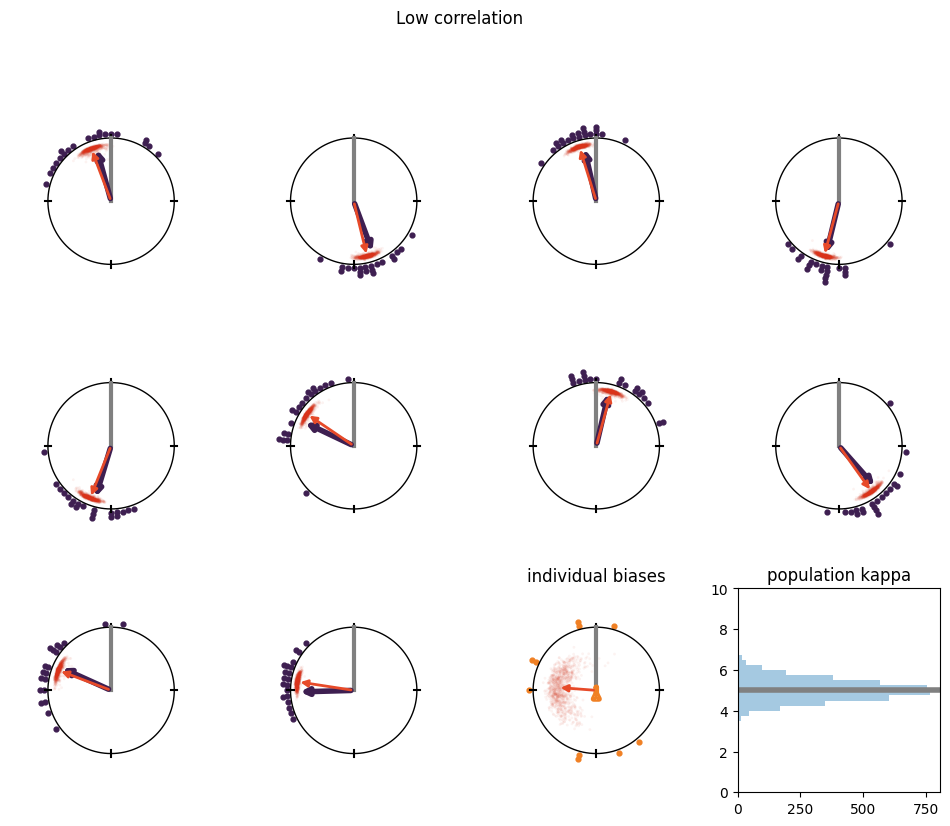

beta0 (deg) 2.5%, 50%, 97.5%: [-141.  -86.  -26.] ; 95% CI width: 115°
softplus(b_kappa_Intercept) > true kappa: 51.2%


In [20]:
plot_individuals(idata_low, dt_low, np.deg2rad(true_low['mu'].values), np.full(len(true_low), 5.0),
                 0.1, 5.0, 'Low correlation')
b0 = draws(idata_low, 'b_beta0_Intercept')
ci_b0 = np.quantile(np.rad2deg(unwrap_circular(b0)), [0.025, 0.5, 0.975])
print('beta0 (deg) 2.5%, 50%, 97.5%:', np.round(ci_b0), f'; 95% CI width: {ci_b0[2] - ci_b0[0]:.0f}°')
print(f"softplus(b_kappa_Intercept) > true kappa: "
      f"{100 * np.mean(softplus_np(draws(idata_low, 'b_kappa_Intercept')) > 5.0):.1f}%")

As for the high-correlation example, the model overestimates $\kappa_\mu$, but recovers accurate estimates of $\beta_i$ and population $\kappa$.
Perhaps unsurprisingly given the set of individual heading biases, the population mean direction $\beta_0$ was not successfully recovered, but the broad credible interval around the estimate suggests considerable uncertainty about the true direction.
This may lead us to ask whether or not there is a shared population mean direction.

## Test shared heading bias hypothesis

A model without $\kappa_\mu$: $\beta_0$ is anchored at 0° and individual biases have a (near) uniform prior, $\beta_i \sim \mathcal{M}(0, \approx 0)$.
A higher target acceptance ratio gives slower, but more robust sampling.

In [21]:
build_nocorr = lambda keep: individual_model(dt_low['y'][keep], dt_low['ID'][keep],
                                             beta0_prior=None, betai_kappa=1e-16)
idata_nocorr = fit(build_nocorr(np.ones(n_low, dtype=bool)), target_accept=0.97)
display(summary(idata_nocorr, ['b_betai', 'b_kappa_Intercept', 'sd_ID__kappa'], ['b_betai']))
loo_low = loo(idata_low, build_low, n_low, 'model_lowcorr')
loo_nocorr = loo(idata_nocorr, build_nocorr, n_low, 'model_nocorr', target_accept=0.97)
print('ELPD difference (kappa_mu - no kappa_mu):', elpd_diff(loo_low, loo_nocorr))
az.compare({'model_lowcorr': loo_low, 'model_nocorr': loo_nocorr})

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat,r_hat_raw
b_betai[1],-0.339,0.116,-0.565,-0.112,0.001,0.002,7411.0,3377.0,1.0,1.00
b_betai[2],2.894,0.100,2.696,3.083,0.001,0.002,5998.0,2840.0,1.0,1.73
b_betai[3],-0.289,0.098,-0.472,-0.081,0.001,0.002,6823.0,2989.0,1.0,1.00
b_betai[4],-2.895,0.105,-3.117,-2.701,0.001,0.002,6573.0,2856.0,1.0,1.73
b_betai[5],-2.777,0.105,-2.982,-2.565,0.001,0.002,5335.0,2590.0,1.0,1.73
b_betai[6],-0.966,0.107,-1.179,-0.764,0.001,0.002,5615.0,3189.0,1.0,1.00
b_betai[7],0.286,0.111,0.077,0.516,0.001,0.002,6104.0,2814.0,1.0,1.00
b_betai[8],2.509,0.109,2.301,2.730,0.001,0.002,5701.0,2728.0,1.0,1.53
b_betai[9],-1.203,0.112,-1.411,-0.975,0.001,0.002,6585.0,3187.0,1.0,1.00
b_betai[10],-1.414,0.099,-1.605,-1.221,0.001,0.002,5883.0,2618.0,1.0,1.00


ELPD difference (kappa_mu - no kappa_mu): -0.0 ± 0.4


,rank,elpd_loo,p_loo,elpd_diff,weight,se,dse,warning,scale
model_nocorr,0,-141.671758,12.258278,0.000000,0.791241,11.439369,0.000000,False,log
model_lowcorr,1,-141.720134,12.185755,0.048376,0.208759,11.498970,0.407575,False,log


Although this dataset was simulated with a von Mises distribution with very low concentration ($\kappa_\mu = 0.1$), the distribution of individual headings does not detectably differ from uniform.
This is plausible for animals without a shared goal direction, and at this level of concentration a considerably larger number of individuals would be needed to recover any group-level bias.
Nonetheless, both models recover the concentration of the average individual's headings ($\kappa \approx 5$).

# Variable individual parameters

<img src="../R/icons/fly.png" width="500">

*Tethered vinegar flies (*Drosophila*) can be induced to fly in a "virtual reality" LED arena, in which their wing motion causes visual cues to rotate. A green light spot induces orientation behaviour, with a weak population level bias towards the light, but highly variable performance across individuals.*

Moderate concentration across individual biases ($\kappa_\mu = 1$), and variable concentration within individuals (mean 1.5, SD 0.5), including a $\approx 0.1\%$ chance of completely uniform heading distributions ($\kappa = 0$).
Despite the modest inter-individual correlation, 4 individuals diverge from the population mean direction by $>90°$, and individual concentrations vary from $\kappa = 1.14$ to $\kappa = 2.66$.
An unbiased (uniform) prior is used for $\beta_0$, $\kappa \sim \mathcal{N}(1, 3)$ (inverse-softplus scale), and $\sigma_\kappa \sim \mathrm{Half}\mathcal{T}(3, 0, 1)$.

In [22]:
dt_var = pd.read_csv(f'{DATA_DIR}/var.csv')
true_var = pd.read_csv(f'{DATA_DIR}/var_true.csv')
idata_var = fit(individual_model(dt_var['y'], dt_var['ID'], beta0_prior='uniform',
                                 kappa_prior=((1, 3),), sd_scale=1.0))
summary(idata_var, ind_vars, ind_circ)

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat,r_hat_raw
b_beta0_Intercept,0.025,0.699,-1.397,1.470,0.068,0.072,124.0,73.0,1.02,1.69
b_betai[1],-0.602,0.704,-2.015,0.831,0.067,0.072,126.0,75.0,1.02,1.68
b_betai[2],-2.907,0.720,-4.394,-1.472,0.068,0.072,127.0,72.0,1.02,1.89
b_betai[3],-1.731,0.710,-3.095,-0.195,0.068,0.073,127.0,78.0,1.02,1.69
b_betai[4],0.336,0.701,-1.004,1.868,0.066,0.070,129.0,77.0,1.02,1.69
b_betai[5],-1.995,0.718,-3.461,-0.500,0.068,0.071,127.0,74.0,1.02,1.69
b_betai[6],2.018,0.718,0.489,3.408,0.068,0.070,128.0,82.0,1.02,2.02
b_betai[7],1.000,0.705,-0.363,2.492,0.067,0.070,126.0,78.0,1.02,1.69
b_betai[8],-0.736,0.702,-2.239,0.646,0.067,0.070,126.0,83.0,1.02,1.68
b_betai[9],1.084,0.706,-0.318,2.608,0.067,0.070,127.0,74.0,1.02,1.69


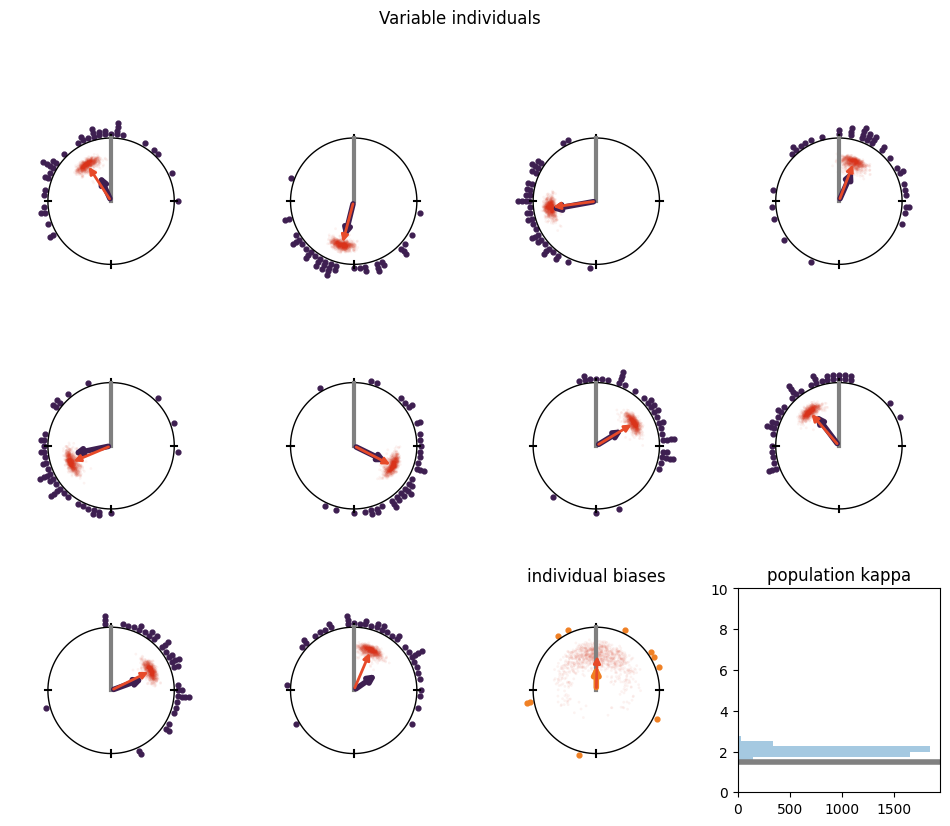

beta0 > 0°: 51.2%


In [23]:
plot_individuals(idata_var, dt_var, np.deg2rad(true_var['mu'].values), true_var['kappa'].values,
                 1.0, 1.5, 'Variable individuals')
print(f"beta0 > 0°: {100 * np.mean(unwrap_circular(draws(idata_var, 'b_beta0_Intercept')) > 0):.1f}%")

The model accounts for individual differences in both directional bias ($\beta_i$) and concentration ($\alpha_i$), and the hyperparameters ($\kappa_\mu$ and $\sigma_\kappa$) are recovered quite accurately.
Individuals with very low concentration and large deviations from the population mean are estimated to be slightly closer to the population mean than their true values (shrinkage).
The population mean direction is recovered, with a wide posterior distribution for $\beta_0$ centred close to the true value.

# Individual heading changes

<img src="../R/icons/bird.png" width="560">

*Birds exhibiting migratory restlessness hop repeatedly in their intended flight direction, allowing this to be recorded repeatedly for the same individuals across multiple nights. Individuals may differ somewhat in their hopping directions, but are generally aligned provided they detect the same compass cues. A treatment that affects their perception of these cues causes the entire population to change their hopping direction.*

The treatment induces a population-level rightwards turn of 30°, although one individual turns to the left, and individual concentrations range from $\kappa = 1.4$ to $\kappa = 8.8$.
The average individual's headings are concentrated ($\kappa = 3$) but vary greatly between individuals ($\sigma_\kappa = 2.5$), and individual biases are highly concentrated ($\kappa_\mu = 4$).

## Fit the models

The treatment $x$ predicts $\beta_0$ (`beta0 ~ 1 + x`), $\beta_i$ (`betai ~ 0 + ID + x:ID`) and $\kappa$ (`kappa ~ 0 + Intercept + x + (1 + x|ID)`).
Individual biases in the control follow $\beta_i \sim \mathcal{M}(0, \kappa_\mu)$, and in the treatment $\beta_i + \beta_{i,x} \sim \mathcal{M}(0, \kappa_{\mu,x})$, where $\kappa_{\mu,x} = \log(\exp(k_{\mu} + k_{\mu,x}) + 1)$ and $k_{\mu,x} \sim \mathcal{N}(0, 1)$.
Models with effects of treatment on $\kappa$ only ('kappa model') and with no effects of treatment ('null model') are fitted for comparison.

In [24]:
dt_hd = pd.read_csv(f'{DATA_DIR}/hd.csv')
true_hd = pd.read_csv(f'{DATA_DIR}/hd_true.csv')
n_hd = len(dt_hd)

def build_hd(keep, mu_x=True, kappa_x=True):
    d = dt_hd[keep]
    if mu_x or kappa_x:
        return individual_model(d['y'], d['ID'], x=d['x'], mu_treatment=mu_x, kappa_treatment=kappa_x,
                                beta0_prior=((0, 3 * np.pi / 2), (0, np.pi / 2)),
                                kappa_prior=((3, 3), (0, 3)), sd_scale=[3.0, 3.0])
    return individual_model(d['y'], d['ID'], kappa_prior=((3, 3),), sd_scale=3.0)

build_hd_treat = lambda keep: build_hd(keep)
build_hd_kappa = lambda keep: build_hd(keep, mu_x=False)
build_hd_null = lambda keep: build_hd(keep, mu_x=False, kappa_x=False)
all_hd = np.ones(n_hd, dtype=bool)
idata_hd_treat = fit(build_hd_treat(all_hd), target_accept=0.97)
idata_hd_kappa = fit(build_hd_kappa(all_hd), target_accept=0.97)
idata_hd_null = fit(build_hd_null(all_hd), target_accept=0.97)

display(summary(idata_hd_treat,
                ['b_beta0_Intercept', 'b_beta0_x', 'b_betai', 'b_betai_x', 'kappa_mu', 'kappa_mu_x',
                 'b_kappa_Intercept', 'b_kappa_x', 'sd_ID__kappa', 'cor_ID__kappa_Intercept__kappa_x'],
                ['b_beta0_Intercept', 'b_beta0_x', 'b_betai', 'b_betai_x']))
display(summary(idata_hd_kappa,
                ['b_beta0_Intercept', 'b_betai', 'kappa_mu', 'b_kappa_Intercept', 'b_kappa_x',
                 'sd_ID__kappa', 'cor_ID__kappa_Intercept__kappa_x'],
                ['b_beta0_Intercept', 'b_betai']))
display(summary(idata_hd_null, ind_vars, ind_circ))
for v in ['b_kappa_x', 'cor_ID__kappa_Intercept__kappa_x']:
    print(f'{v} 95% CI: ' + ' to '.join(f'{q:.2f}' for q in np.quantile(draws(idata_hd_treat, v), [0.025, 0.975])))

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat,r_hat_raw
b_beta0_Intercept,-0.159,0.220,-0.613,0.264,0.007,0.005,968.0,1312.0,1.01,1.01
b_beta0_x,0.856,0.338,0.149,1.487,0.012,0.009,812.0,1076.0,1.01,1.01
b_betai[1],-0.095,0.274,-0.608,0.453,0.007,0.005,1773.0,2340.0,1.00,1.00
b_betai[2],0.253,0.244,-0.201,0.750,0.007,0.005,1206.0,1714.0,1.01,1.01
b_betai[3],-0.200,0.230,-0.641,0.269,0.007,0.005,1052.0,1369.0,1.01,1.01
b_betai[4],0.108,0.262,-0.396,0.640,0.007,0.005,1446.0,2057.0,1.01,1.01
b_betai[5],-0.109,0.235,-0.572,0.338,0.007,0.005,1107.0,1627.0,1.01,1.01
b_betai_x[1],-0.452,0.406,-1.261,0.363,0.011,0.008,1356.0,1546.0,1.01,1.01
b_betai_x[2],0.248,0.364,-0.469,0.957,0.012,0.008,921.0,1282.0,1.01,1.01
b_betai_x[3],0.573,0.348,-0.125,1.232,0.012,0.009,846.0,1227.0,1.01,1.01


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat,r_hat_raw
b_beta0_Intercept,0.649,0.247,0.169,1.134,0.007,0.006,1171.0,1506.0,1.01,1.01
b_betai[1],-0.660,0.275,-1.241,-0.161,0.007,0.006,1494.0,1943.0,1.01,1.01
b_betai[2],0.297,0.280,-0.254,0.860,0.007,0.005,1539.0,1978.0,1.00,1.00
b_betai[3],0.385,0.255,-0.071,0.933,0.007,0.006,1211.0,1612.0,1.01,1.01
b_betai[4],-0.954,0.273,-1.480,-0.411,0.007,0.006,1432.0,1950.0,1.00,1.00
b_betai[5],0.780,0.257,0.284,1.286,0.007,0.006,1228.0,1757.0,1.01,1.01
kappa_mu,5.124,1.903,1.995,8.981,0.036,0.044,3692.0,2290.0,1.00,1.00
b_kappa_Intercept,0.660,0.838,-1.019,2.337,0.024,0.018,1286.0,1668.0,1.00,1.00
b_kappa_x,3.024,2.060,-1.187,6.813,0.054,0.039,1503.0,2026.0,1.00,1.00
sd_ID__kappa[Intercept],1.824,0.961,0.306,3.727,0.024,0.025,1462.0,2028.0,1.00,1.00


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat,r_hat_raw
b_beta0_Intercept,0.259,0.158,-0.046,0.571,0.006,0.004,731.0,1109.0,1.01,1.01
b_betai[1],-0.295,0.193,-0.680,0.073,0.006,0.003,1194.0,1663.0,1.00,1.00
b_betai[2],0.367,0.182,0.014,0.725,0.006,0.003,948.0,1857.0,1.00,1.00
b_betai[3],0.099,0.183,-0.276,0.447,0.006,0.003,1107.0,1441.0,1.00,1.00
b_betai[4],-0.493,0.190,-0.847,-0.109,0.006,0.004,1177.0,1308.0,1.00,1.00
b_betai[5],0.310,0.196,-0.104,0.667,0.006,0.003,1175.0,1696.0,1.00,1.00
kappa_mu,11.013,5.202,3.035,21.452,0.154,0.223,1878.0,994.0,1.00,1.00
b_kappa_Intercept,1.664,0.303,1.059,2.267,0.008,0.010,1515.0,1373.0,1.00,1.00
sd_ID__kappa,0.439,0.385,0.000,1.170,0.012,0.013,961.0,1379.0,1.00,1.00
r_ID__kappa[1],-0.144,0.351,-1.016,0.474,0.009,0.008,1777.0,2164.0,1.00,1.00


b_kappa_x 95% CI: -0.52 to 4.60
cor_ID__kappa_Intercept__kappa_x 95% CI: -0.65 to 0.99


For `b_kappa_x` there is substantial posterior density for both increases and decreases in concentration in the treatment condition, and the range of estimates for `kappa_mu_x` largely overlaps with that for `kappa_mu` in the control condition.
The correlation between individual differences in concentration in the control and in their response to treatment also has substantial posterior density for both correlation and anti-correlation, so there is no clear evidence of a relationship between variation in the two conditions (correctly, since none was simulated).

## Test hypothesis of treatment effect

The model comparison uses PSIS-LOO, with exact refits for observations with high Pareto $\hat{k}$.

model_hd_kappa: 2 observation(s) with Pareto k > 0.7, refitting without them
model_hd_treatment: 1 observation(s) with Pareto k > 0.7, refitting without them


,rank,elpd_loo,p_loo,elpd_diff,weight,se,dse,warning,scale
model_hd_treatment,0,-187.231420,16.950470,0.000000,9.817313e-01,12.997285,0.000000,False,log
model_hd_kappa,1,-248.901792,15.195785,61.670372,4.570721e-15,12.555055,8.263480,False,log
model_hd_null,2,-270.012767,7.140361,82.781348,1.826874e-02,8.886540,10.944647,False,log


ELPD difference (mu & kappa - kappa): 61.7 ± 8.3
ELPD difference (mu & kappa - null): 82.8 ± 11.0


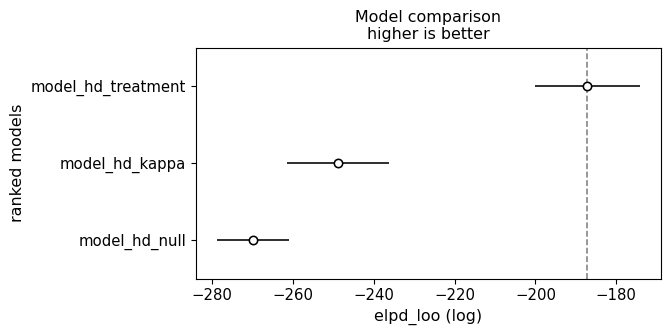

In [25]:
loo_hd = {'model_hd_null': loo(idata_hd_null, build_hd_null, n_hd, 'model_hd_null', 0.97),
          'model_hd_kappa': loo(idata_hd_kappa, build_hd_kappa, n_hd, 'model_hd_kappa', 0.97),
          'model_hd_treatment': loo(idata_hd_treat, build_hd_treat, n_hd, 'model_hd_treatment', 0.97)}
comp_hd = az.compare(loo_hd)
display(comp_hd)
print('ELPD difference (mu & kappa - kappa):', elpd_diff(loo_hd['model_hd_treatment'], loo_hd['model_hd_kappa']))
print('ELPD difference (mu & kappa - null):', elpd_diff(loo_hd['model_hd_treatment'], loo_hd['model_hd_null']))
az.plot_compare(comp_hd)
plt.show()

## Plot model predictions

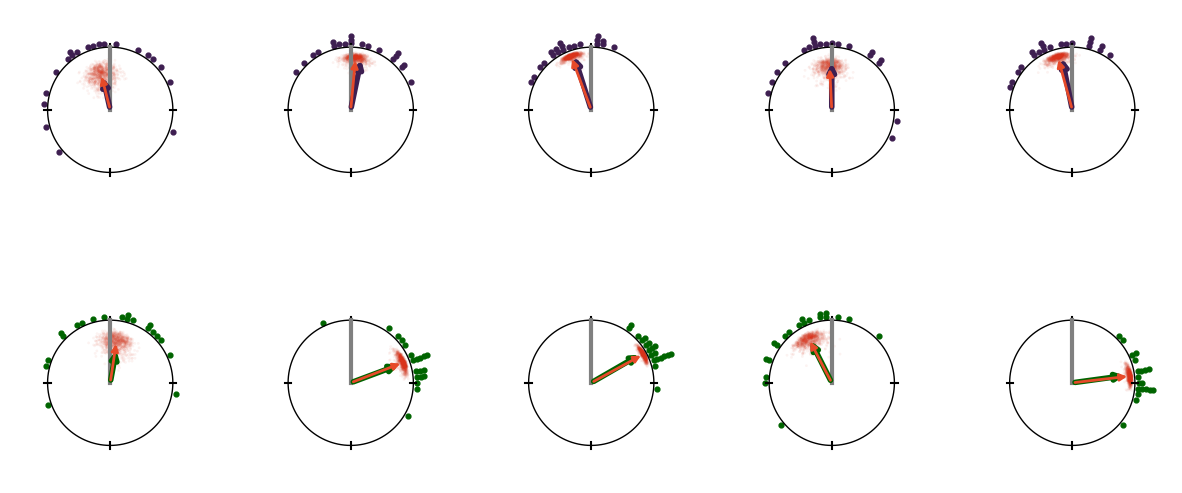

In [26]:
b0, b0x = draws(idata_hd_treat, 'b_beta0_Intercept'), draws(idata_hd_treat, 'b_beta0_x')
k0, k0x = draws(idata_hd_treat, 'b_kappa_Intercept'), draws(idata_hd_treat, 'b_kappa_x')
J = len(true_hd)
fig, axs = plt.subplots(2, J, figsize=(3 * J, 6.5))
for i, idv in enumerate(idata_hd_treat.posterior['ID'].values):
    bi = draws(idata_hd_treat, 'b_betai', ID=idv)
    bix = draws(idata_hd_treat, 'b_betai_x', ID=idv)
    ri = draws(idata_hd_treat, 'r_ID__kappa', ID=idv, re='Intercept')
    rix = draws(idata_hd_treat, 'r_ID__kappa', ID=idv, re='x')
    for row, cond, mu, kp, mu_t, col in [
            (0, 0, b0 + bi, softplus_np(k0 + ri), true_hd['mu'][i], col_obs),
            (1, 1, b0 + b0x + bi + bix, softplus_np(k0 + k0x + ri + rix), true_hd['mu_delta'][i], col_treat)]:
        ax = axs[row, i]; circ_base(ax)
        circ_points(ax, dt_hd['y'][(dt_hd['ID'] == idv) & (dt_hd['x'] == cond)].values, col)
        draw_cloud(ax, mu, kp)
        circ_arrow(ax, np.deg2rad(mu_t), A1(true_hd['kappa'][i]), col, 4)
        circ_arrow(ax, circ_median(mu), A1(np.median(kp)), col_sd, 2)
plt.show()

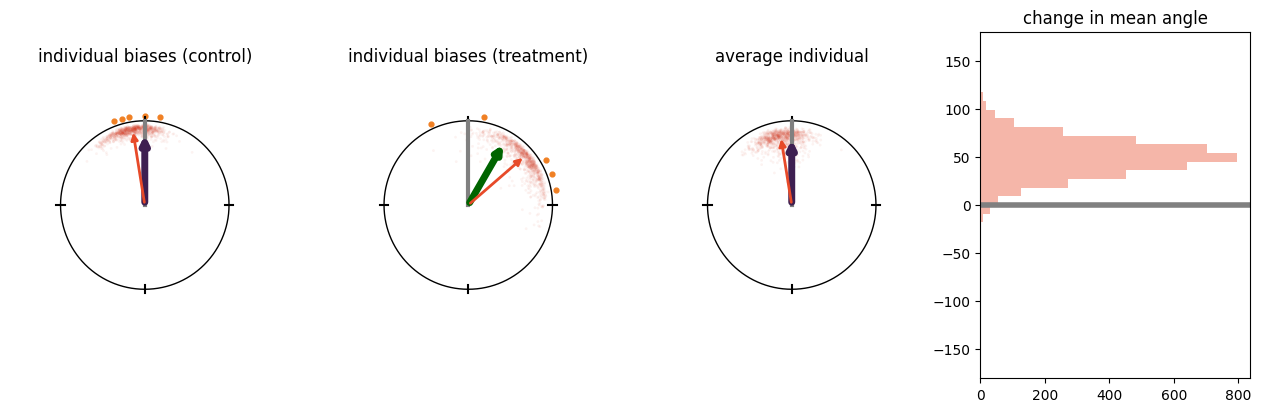

Rightwards turn: 99.0% of estimates
95% CI of the turn: 9° to 86° (true turn 30°)


In [27]:
kmu, kmux = draws(idata_hd_treat, 'kappa_mu'), draws(idata_hd_treat, 'kappa_mu_x')
fig, axs = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, mu_t, mu_draws, k_draws, k_true, col, title in [
        (axs[0], true_hd['mu'], b0, kmu, 4.0, col_obs, 'individual biases (control)'),
        (axs[1], true_hd['mu_delta'], b0x, kmux, 4.0, col_treat, 'individual biases (treatment)')]:
    circ_base(ax); ax.set_title(title)
    circ_points(ax, np.deg2rad(mu_t.values), col_rho)
    circ_arrow(ax, 0.0 if col == col_obs else np.deg2rad(30), A1(k_true), col, 5)
    draw_cloud(ax, mu_draws, k_draws)
    circ_arrow(ax, circ_mean(mu_draws), A1(np.median(k_draws)), col_sd, 2)
circ_base(axs[2]); axs[2].set_title('average individual')
circ_arrow(axs[2], 0.0, A1(3.0), col_obs, 5)
draw_cloud(axs[2], b0, softplus_np(k0))
circ_arrow(axs[2], circ_mean(b0), A1(np.median(softplus_np(k0))), col_sd, 2)
vert_hist(axs[3], np.rad2deg(unwrap_circular(b0x)), 'change in mean angle', (-180, 180), col_sd)
plt.show()
print(f'Rightwards turn: {100 * np.mean(wrap_pi(b0x) > 0):.1f}% of estimates')
print('95% CI of the turn: {:.0f}° to {:.0f}° (true turn 30°)'.format(*np.quantile(np.rad2deg(unwrap_circular(b0x)), [0.025, 0.975])))

The model comparison clearly favours an effect of treatment on both $\mu$ and $\kappa$, and the estimates of the population mean angle favour a right turn, but there is a lot of uncertainty about the exact size of the turn.
This is influenced by the wide spread of individual mean angles and turn angles.

# Summary

- Circular GLMs can be used to model effects on mean direction $\mu$ and concentration $\kappa$.
- The posterior density of parameter estimates can be compared with expected values; for example, an expected angle (such as the 'home direction') or concentration.
- Where expected values of $\mu$ and $\kappa$ are not known, fitted estimates can be compared between data for control and treatment conditions as an offset parameter between the two.
- Grouping factors, such as individual biases, can be accounted for in a hierarchical model, and the properties of the population of individuals estimated as hyperparameters for the concentration of individual mean directions ($\kappa_\mu$) and standard deviation of individual concentrations ($\sigma_\kappa$).
- Competing hypotheses about effects within a dataset can be formalised as circular GLMs with differing parameters, and their plausibility contrasted directly *via* model-comparison methods such as expected log predictive density.